In [1]:
import pandas as pd
from DataUtils import *

In [21]:
df = pd.read_csv('ScrapedData/kletterschuhe_raw.csv')

for col in df.columns:
    df[col] = df[col].apply(eval_string_data)

df.info()

df.head(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 291 entries, 0 to 290
Data columns (total 33 columns):
 #   Column                                                          Non-Null Count  Dtype 
---  ------                                                          --------------  ----- 
 0   Unnamed: 0                                                      291 non-null    int64 
 1   shortDescription                                                291 non-null    object
 2   longDescription                                                 291 non-null    object
 3   availableSizes                                                  291 non-null    object
 4   Geeignet für                                                    291 non-null    object
 5   Sportart                                                        289 non-null    object
 6   Kletteranspruch                                                 291 non-null    object
 7   Vorspannung                                                   

,Unnamed: 0,shortDescription,longDescription,availableSizes,Geeignet für,Sportart,Kletteranspruch,Vorspannung,Downturn,Asymmetrie,...,Vibram®,Bergzeit Empfehlung,Nachhaltige Produktmerkmale (Details s. Digitaler Produktpass),Auszeichnungen,Passformangabe Hersteller,Produkteigenschaften,Größeninformation,Profiltiefe,Material,Schafthöhe
0,0,Komfortabler Kletterschuh mit intuitiver Passf...,Der HyperEZ wurde speziell für Klettereinsteig...,"[36, 36.5, 37, 37.5, 38, 38.5, 39, 39.5, 40, 4...","[Damen, Herren]",[Sportklettern],"[ambitionierte Kletterer, Klettereinsteiger]",[keine Vorspannung],[ohne Downturn],[wenig asymmetrisch],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,Bequemer Damen-Kletterschuh mit Schnürung für ...,Der Women’s Momentum Lace von Black Diamond is...,"[US 7.5, US 7.5+, US 8, US 10]",[Damen],"[Bouldern, Sportklettern]",[ambitionierte Kletterer],[wenig Vorspannung],[ohne Downturn],[wenig asymmetrisch],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
df['availableSizes'] = df['availableSizes'].apply(convert_size_list)
df.head(2)

,Unnamed: 0,shortDescription,longDescription,availableSizes,Geeignet für,Sportart,Kletteranspruch,Vorspannung,Downturn,Asymmetrie,...,Vibram®,Bergzeit Empfehlung,Nachhaltige Produktmerkmale (Details s. Digitaler Produktpass),Auszeichnungen,Passformangabe Hersteller,Produkteigenschaften,Größeninformation,Profiltiefe,Material,Schafthöhe
0,0,Komfortabler Kletterschuh mit intuitiver Passf...,Der HyperEZ wurde speziell für Klettereinsteig...,"[36.0, 36.5, 37.0, 37.5, 38.0, 38.5, 39.0, 39....","[Damen, Herren]",[Sportklettern],"[ambitionierte Kletterer, Klettereinsteiger]",[keine Vorspannung],[ohne Downturn],[wenig asymmetrisch],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,Bequemer Damen-Kletterschuh mit Schnürung für ...,Der Women’s Momentum Lace von Black Diamond is...,"[39.5, 39.5, 40.0, 42.0]",[Damen],"[Bouldern, Sportklettern]",[ambitionierte Kletterer],[wenig Vorspannung],[ohne Downturn],[wenig asymmetrisch],...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
columns_to_explode = ['availableSizes', 'Geeignet für', 'Sportart', 'Vorspannung', 'Downturn']

i = 0
for col in df.columns:
    if (i == 0):
        df_exploded = df.explode(col, ignore_index = True)
    else:
        df_exploded = df_exploded.explode(col, ignore_index = True)
    i += 1


df_exploded

,Unnamed: 0,shortDescription,longDescription,availableSizes,Geeignet für,Sportart,Kletteranspruch,Vorspannung,Downturn,Asymmetrie,...,Vibram®,Bergzeit Empfehlung,Nachhaltige Produktmerkmale (Details s. Digitaler Produktpass),Auszeichnungen,Passformangabe Hersteller,Produkteigenschaften,Größeninformation,Profiltiefe,Material,Schafthöhe
0,0,Komfortabler Kletterschuh mit intuitiver Passf...,Der HyperEZ wurde speziell für Klettereinsteig...,36.0,Damen,Sportklettern,ambitionierte Kletterer,keine Vorspannung,ohne Downturn,wenig asymmetrisch,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,Komfortabler Kletterschuh mit intuitiver Passf...,Der HyperEZ wurde speziell für Klettereinsteig...,36.0,Damen,Sportklettern,ambitionierte Kletterer,keine Vorspannung,ohne Downturn,wenig asymmetrisch,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0,Komfortabler Kletterschuh mit intuitiver Passf...,Der HyperEZ wurde speziell für Klettereinsteig...,36.0,Damen,Sportklettern,ambitionierte Kletterer,keine Vorspannung,ohne Downturn,wenig asymmetrisch,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0,Komfortabler Kletterschuh mit intuitiver Passf...,Der HyperEZ wurde speziell für Klettereinsteig...,36.0,Damen,Sportklettern,ambitionierte Kletterer,keine Vorspannung,ohne Downturn,wenig asymmetrisch,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,Komfortabler Kletterschuh mit intuitiver Passf...,Der HyperEZ wurde speziell für Klettereinsteig...,36.0,Damen,Sportklettern,ambitionierte Kletterer,keine Vorspannung,ohne Downturn,wenig asymmetrisch,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145252,290,Sensibler Kletterschuh für modernes Bouldern u...,MIt dem Shaman Pro LV von Evolv kannst du dein...,36.5,Herren,Sportklettern,ambitionierte Kletterer,mittlere Vorspannung,mit Downturn,stark asymmetrisch,...,NaN,+1 Fortgeschrittene: Bestelle eine Größe größe...,veganes Produkt (Herstellerangabe),NaN,Low Volume,NaN,fällt kleiner aus,NaN,NaN,NaN
145253,290,Sensibler Kletterschuh für modernes Bouldern u...,MIt dem Shaman Pro LV von Evolv kannst du dein...,36.5,Herren,Sportklettern,ambitionierte Kletterer,mittlere Vorspannung,mit Downturn,stark asymmetrisch,...,NaN,+2 Einsteiger: Bestelle zwei Größen größer als...,veganes Produkt (Herstellerangabe),NaN,Low Volume,NaN,fällt kleiner aus,NaN,NaN,NaN
145254,290,Sensibler Kletterschuh für modernes Bouldern u...,MIt dem Shaman Pro LV von Evolv kannst du dein...,36.5,Herren,Sportklettern,ambitionierte Kletterer,mittlere Vorspannung,mit Downturn,stark asymmetrisch,...,NaN,+ 0 Profis: Bestelle die gleiche Größe wie Dei...,veganes Produkt (Herstellerangabe),NaN,Low Volume,NaN,fällt kleiner aus,NaN,NaN,NaN
145255,290,Sensibler Kletterschuh für modernes Bouldern u...,MIt dem Shaman Pro LV von Evolv kannst du dein...,36.5,Herren,Sportklettern,ambitionierte Kletterer,mittlere Vorspannung,mit Downturn,stark asymmetrisch,...,NaN,+1 Fortgeschrittene: Bestelle eine Größe größe...,veganes Produkt (Herstellerangabe),NaN,Low Volume,NaN,fällt kleiner aus,NaN,NaN,NaN


In [27]:
df_exploded.drop_duplicates(inplace = True)
df_exploded

,Unnamed: 0,shortDescription,longDescription,availableSizes,Geeignet für,Sportart,Kletteranspruch,Vorspannung,Downturn,Asymmetrie,...,Vibram®,Bergzeit Empfehlung,Nachhaltige Produktmerkmale (Details s. Digitaler Produktpass),Auszeichnungen,Passformangabe Hersteller,Produkteigenschaften,Größeninformation,Profiltiefe,Material,Schafthöhe
0,0,Komfortabler Kletterschuh mit intuitiver Passf...,Der HyperEZ wurde speziell für Klettereinsteig...,36.0,Damen,Sportklettern,ambitionierte Kletterer,keine Vorspannung,ohne Downturn,wenig asymmetrisch,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,Komfortabler Kletterschuh mit intuitiver Passf...,Der HyperEZ wurde speziell für Klettereinsteig...,36.0,Damen,Sportklettern,ambitionierte Kletterer,keine Vorspannung,ohne Downturn,wenig asymmetrisch,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0,Komfortabler Kletterschuh mit intuitiver Passf...,Der HyperEZ wurde speziell für Klettereinsteig...,36.0,Damen,Sportklettern,ambitionierte Kletterer,keine Vorspannung,ohne Downturn,wenig asymmetrisch,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0,Komfortabler Kletterschuh mit intuitiver Passf...,Der HyperEZ wurde speziell für Klettereinsteig...,36.0,Damen,Sportklettern,ambitionierte Kletterer,keine Vorspannung,ohne Downturn,wenig asymmetrisch,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,Komfortabler Kletterschuh mit intuitiver Passf...,Der HyperEZ wurde speziell für Klettereinsteig...,36.0,Damen,Sportklettern,ambitionierte Kletterer,keine Vorspannung,ohne Downturn,wenig asymmetrisch,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145252,290,Sensibler Kletterschuh für modernes Bouldern u...,MIt dem Shaman Pro LV von Evolv kannst du dein...,36.5,Herren,Sportklettern,ambitionierte Kletterer,mittlere Vorspannung,mit Downturn,stark asymmetrisch,...,NaN,+1 Fortgeschrittene: Bestelle eine Größe größe...,veganes Produkt (Herstellerangabe),NaN,Low Volume,NaN,fällt kleiner aus,NaN,NaN,NaN
145253,290,Sensibler Kletterschuh für modernes Bouldern u...,MIt dem Shaman Pro LV von Evolv kannst du dein...,36.5,Herren,Sportklettern,ambitionierte Kletterer,mittlere Vorspannung,mit Downturn,stark asymmetrisch,...,NaN,+2 Einsteiger: Bestelle zwei Größen größer als...,veganes Produkt (Herstellerangabe),NaN,Low Volume,NaN,fällt kleiner aus,NaN,NaN,NaN
145254,290,Sensibler Kletterschuh für modernes Bouldern u...,MIt dem Shaman Pro LV von Evolv kannst du dein...,36.5,Herren,Sportklettern,ambitionierte Kletterer,mittlere Vorspannung,mit Downturn,stark asymmetrisch,...,NaN,+ 0 Profis: Bestelle die gleiche Größe wie Dei...,veganes Produkt (Herstellerangabe),NaN,Low Volume,NaN,fällt kleiner aus,NaN,NaN,NaN
145255,290,Sensibler Kletterschuh für modernes Bouldern u...,MIt dem Shaman Pro LV von Evolv kannst du dein...,36.5,Herren,Sportklettern,ambitionierte Kletterer,mittlere Vorspannung,mit Downturn,stark asymmetrisch,...,NaN,+1 Fortgeschrittene: Bestelle eine Größe größe...,veganes Produkt (Herstellerangabe),NaN,Low Volume,NaN,fällt kleiner aus,NaN,NaN,NaN


In [29]:
df_exploded.to_excel('ScrapedData/cleaned_data.xlsx')

In [35]:
geeignet_fur = df_exploded[['Geeignet für', 'shortDescription']].groupby('Geeignet für', as_index = False).count()
geeignet_fur

,Geeignet für,shortDescription
0,Damen,72618
1,Herren,69785
2,Kinder,2068


<Axes: xlabel='Geeignet für', ylabel='shortDescription'>

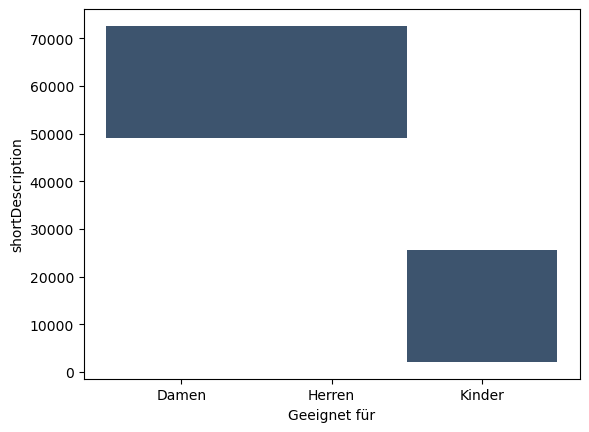

In [43]:
import seaborn as sns

sns.histplot(geeignet_fur, x = 'Geeignet für', y = 'shortDescription')

In [40]:
dir(sns)

['FacetGrid',
 'JointGrid',
 'PairGrid',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__path__',
 '__spec__',
 '__version__',
 '_base',
 '_compat',
 '_core',
 '_docstrings',
 '_orig_rc_params',
 '_statistics',
 '_stats',
 'algorithms',
 'axes_style',
 'axisgrid',
 'barplot',
 'blend_palette',
 'boxenplot',
 'boxplot',
 'categorical',
 'catplot',
 'choose_colorbrewer_palette',
 'choose_cubehelix_palette',
 'choose_dark_palette',
 'choose_diverging_palette',
 'choose_light_palette',
 'clustermap',
 'cm',
 'color_palette',
 'colors',
 'countplot',
 'crayon_palette',
 'crayons',
 'cubehelix_palette',
 'dark_palette',
 'desaturate',
 'despine',
 'displot',
 'distplot',
 'distributions',
 'diverging_palette',
 'dogplot',
 'ecdfplot',
 'external',
 'get_data_home',
 'get_dataset_names',
 'heatmap',
 'histplot',
 'hls_palette',
 'husl_palette',
 'jointplot',
 'kdeplot',
 'light_palette',
 'lineplot',
 'lmplot',
 'load_dataset',
 'matrix